In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
df = pd.read_csv("/emails.csv")

In [ ]:
print("Dataset shape:", df.shape)
print(df.head())
print("Missing values:", df.isnull().sum().sum())
df = df.drop_duplicates().dropna()
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1].astype(int)
print("\nClass distribution:")
print(y.value_counts())

Dataset shape: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
Missing values: 0

Class distribut

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)
svm = SVC(kernel="linear", C=1.0)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

In [ ]:
results = {}
for name, y_pred in [
    ("KNN", knn_pred),
    ("SVM", svm_pred)
]:
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Error Rate": 1 - accuracy_score(y_test, y_pred)
    }

    print(f"\n{name} Classification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Not Spam", "Spam"],
        zero_division=0
    ))


KNN Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


SVM Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.98      0.97      0.98       735
        Spam       0.94      0.95      0.94       300

    accuracy                           0.97      1035
   macro avg       0.96      0.96      0.96      1035
weighted avg       0.97      0.97      0.97      1035



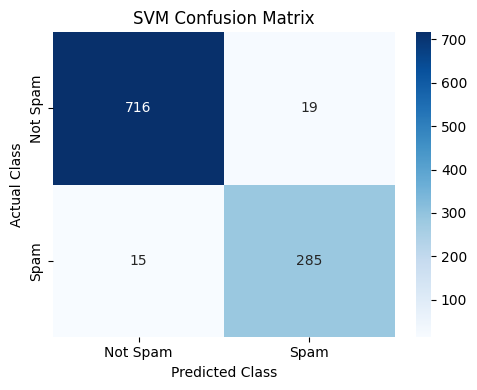

In [ ]:
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Spam", "Spam"],
        yticklabels=["Not Spam", "Spam"]
    )
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.show()


Model Performance Comparison:
    Accuracy Precision  Recall F1-Score Error Rate
KNN   83.38%    64.35%  95.67%   76.94%     16.62%
SVM   96.71%    93.75%   95.0%   94.37%      3.29%


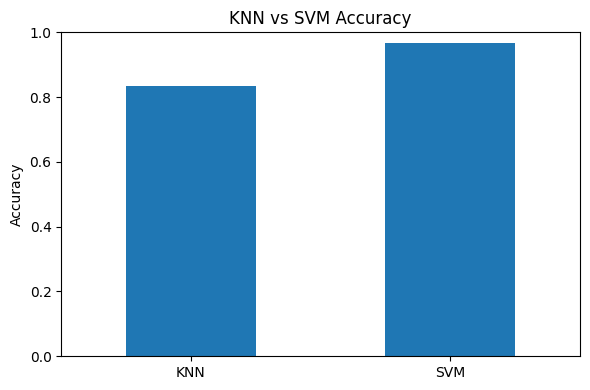

In [ ]:
comparison = pd.DataFrame(results).T
print("\nModel Performance Comparison:")
print((comparison * 100).round(2).astype(str) + "%")
comparison["Accuracy"].plot(
    kind="bar",
    figsize=(6, 4),
    rot=0,
    title="KNN vs SVM Accuracy"
)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()